In [84]:
import numpy as np
import sys
import scipy
from numpy.fft import fft, ifft, fftfreq
import matplotlib.pyplot as plt
from scipy.special import expi
np.set_printoptions(threshold=sys.maxsize)

## GPE : 
$$i \hbar \frac{ \partial \psi }{ \partial t }=\underbrace{-\frac{\hbar^{2}}{2m}\nabla\psi}_{\text{Kinetic}}+\underbrace{A\frac{x^{2}}{2}\psi}_{\text{Trapping Potential}}+\underbrace{g|\psi|^{2}\psi}_{\text{lattice interaction}}$$ 
using imaginary time evolution $t \to-i\tau$
$$\begin{align}
i \hbar \frac{ \partial \psi }{ \partial (-i\tau) }&=-\frac{\hbar^{2}}{2m}\nabla\psi+A\frac{x^{2}}{2}\psi+{g|\psi|^{2}\psi}\\ - \frac{ \partial \psi }{ \partial \tau } &=- \frac{\hbar}{2m}\nabla \psi +A\frac{x^{2}}{2}\psi +g|\psi|^{2}\psi
\end{align}$$
#### Time Splitting Time Method
1. Kinetic Part -> solve using FFT $$d\psi=- \frac{\hbar}{2m}\nabla \psi \tag{1} (-d\tau)$$ 
2. Trapping potential and Lattice Interaction $$\begin{align}d\psi = \frac{Ax^{2}}{2}\psi+g|\psi|^{2}\psi(-d\tau) \tag{2} \\ \int_{\psi_{j}^n}^{\psi_{j}^{n+1}} \frac{1}{\psi} d\psi =\int_{\tau}^{\tau+\Delta \tau} A\frac{x^{2}}{2}+g |\psi|^{2}(-d\tau)  \\  \ln \frac{\psi_{j}^{n+1}}{\psi_{j}^n} =(\frac{Ax^{2}}{2}+g|\psi|^{2} )(-\Delta \tau) \\  \psi_{j}^{n+1}=\psi_{j}^ne^{ (\frac{Ax^{2}}{2}+g|\psi|^{2} )(-\Delta \tau) }\end{align}$$

### Energy 
$$E(\psi)=\int  \left[\frac{\hbar}{2m}|\nabla \psi ({x})|^{2}+V({x}) |\psi({x})|^{2}+\frac{1}{2}U_{0}|\psi({x})|^4\right]d{x}$$

To check for Energy Convergence, $$E_{n+1}-E_n < 1\times 10^{-13}$$

In [264]:
dx = 0.001; #space steps 
x = np.arange(-7.5, 7.5, dx) # space array

dt = 1e-3 #time step
no_tsteps = int(100/dt) 

A=1 # Harmonic trap strength
g=100 # interaction strength

psi = np.zeros(len(x), dtype=complex)

gamma = (1+1j) # imaginary time (if gamma = 0 -> real time ) 
c0 = dt / (1j - gamma) # -dt 

wavenumbers = 2*np.pi*fftfreq(len(x), d=dx) # wavenumbers 'grid'

V = 0.5*A*x**2 # trapping potential 
kinetic_array = np.exp(c0 * 0.5 * wavenumbers**2) #kinetic

def normalize(psi) : 
    return psi/np.sqrt(np.sum(np.abs(psi) ** 2) * dx)

def DDI(psi, U) : 
    Phi = ifft(U*fft(np.abs(psi)**2))
    return Phi

def kinetic(psi) : 
    psi = ifft(fft(psi)*kinetic_array) # kinetic evolution (USing FFT) 
    return psi

def local(psi) :
    psi_density = np.abs(psi)**2
    Phi = DDI(psi, U) 
    psi *= np.exp(c0*(V+g*psi_density)) # Trapping Potential + Interaction
    return psi 

def evolution(psi): 
    psi = kinetic(psi)
    psi = local(psi)

    psi = normalize(psi)
    return psi

def energy(psi):
    dpsi = (np.roll(psi, -1) - np.roll(psi, 1)) / (2 *dx) #centered finite difference
    #dpsi = ifft(1j * wavenumbers * fft(psi))
    E_kinetic = 0.5 * np.sum(np.abs(dpsi)**2) * dx
    E_potential = np.sum(V * np.abs(psi)**2) * dx
    E_interaction = 0.5 * g * np.sum(np.abs(psi)**4) * dx
    return E_kinetic, E_potential , E_interaction

psi=(np.exp(-0.5 * x**2) / np.pi**0.25).astype(complex) #initial state (From Gaussian Shape)
psi = normalize(psi)

# energy convergence 
E_prev = sum(energy(psi))
print(f"Initial Energy E_0 = {E_prev:.10f}")

for i in range(no_tsteps): 
    psi = evolution(psi)
    E_kinetic, E_potential , E_interaction = energy(psi)
    E_curr = E_kinetic+ E_potential + E_interaction

    E_diff = abs(E_curr - E_prev) 

    if i % 1000 == 0 or E_diff < 1e-13 : 
        print(f"step {i} = {E_curr:.13f}") 
        print(f"Potential Energy : {E_potential:.13f} | Kinetic Energy : {E_kinetic:.13f} | Interaction : {E_interaction:.13f}\n")

    if E_diff < 1e-13 : 
        print(f"\nConvergence achieved at step {i}!")
        print(f"Ground State Energy E_g  = {E_curr:.13f}")
        
        break

    E_prev = E_curr
        

Initial Energy E_0 = 20.4471138951
step 0 = 19.9631097771286
Potential Energy : 0.2601440182308 | Kinetic Energy : 0.2404704490416 | Interaction : 19.4624953098561

step 1000 = 8.5122282017101
Potential Energy : 2.7639334321208 | Kinetic Energy : 0.0396428059761 | Interaction : 5.7086519636133

step 2000 = 8.5085286343039
Potential Energy : 2.8462793466442 | Kinetic Energy : 0.0350570379319 | Interaction : 5.6271922497278

step 3000 = 8.5085267744542
Potential Energy : 2.8477935508435 | Kinetic Energy : 0.0349589526643 | Interaction : 5.6257742709464

step 4000 = 8.5085267682590
Potential Energy : 2.8478219365855 | Kinetic Energy : 0.0349570846532 | Interaction : 5.6257477470203

step 4359 = 8.5085267681764
Potential Energy : 2.8478223515097 | Kinetic Energy : 0.0349570573254 | Interaction : 5.6257473593413


Convergence achieved at step 4359!
Ground State Energy E_g  = 8.5085267681764


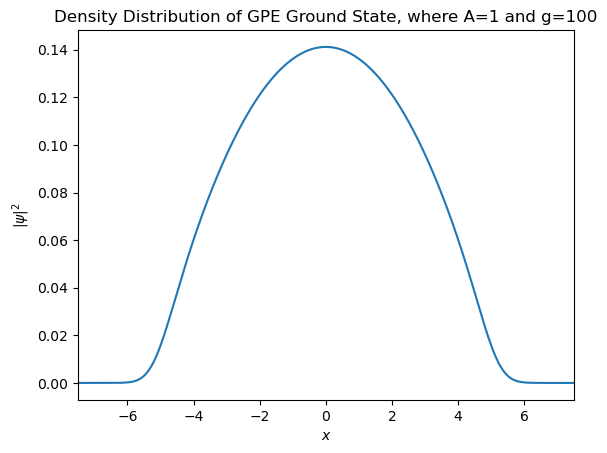

In [266]:
plt.plot(x, np.abs(psi)**2) 
plt.xlim(-7.5, 7.5)
plt.ylabel (r'$|\psi|^2$')
plt.xlabel (r'$x$')
#plt.ylim (0, 0.6) 
plt.title(f"Density Distribution of GPE Ground State, where A={A} and g={g}")

plt.savefig('DensityDistwDDI_A1_g1.png', dpi=500, bbox_inches='tight') 
plt.show()

In [149]:
dx = 0.001
x = np.arange(-7.5, 7.5, dx)
wavenumbers = 2*np.pi*fftfreq(len(x), d=dx) # wavenumbers 'grid'

def groundstateGPE (A, g) : 
    dx = 0.001; #space steps 
    x = np.arange(-7.5, 7.5, dx) # space array
    
    dt = 1e-3 #time step
    no_tsteps = int(100/dt) 
    
    psi = np.zeros(len(x), dtype=complex)
    
    gamma = (1+1j) # imaginary time 
    c0 = dt / (1j - gamma) # -dt 
    
    wavenumbers = 2*np.pi*fftfreq(len(x), d=dx) # wavenumbers 'grid'
    
    V = 0.5*A*x**2 # trapping potential 
    kinetic = np.exp(c0 * 0.5 * wavenumbers**2) #kinetic
    
    def normalize(psi) : 
        return psi/np.sqrt(np.sum(np.abs(psi) ** 2) * dx)
                
    def evolution(psi): 
        psi_density = np.abs(psi)**2
        psi = ifft(fft(psi)*kinetic) # kinetic evolution (USing FFT) 
        psi *= np.exp(c0*(V+g*psi_density)) # Trapping Potential + Interaction
    
        psi = normalize(psi)
        return psi
    
    def energy(psi):
        dpsi = (np.roll(psi, -1) - np.roll(psi, 1)) / (2 *dx)  # spectral derivative
        #dpsi = ifft(1j * wavenumbers * fft(psi))
        E_kinetic = 0.5 * np.sum(np.abs(dpsi)**2) * dx
        E_potential = np.sum(V * np.abs(psi)**2) * dx
        E_interaction = 0.5 * g * np.sum(np.abs(psi)**4) * dx
        return E_kinetic, E_potential , E_interaction
    
    psi=(np.exp(-0.5 * x**2) / np.pi**0.25).astype(complex) #initial state (From Gaussian Shape)
    psi = normalize(psi)
    
    # energy convergence 
    E_prev = sum(energy(psi) )
    #print(f"Initial Energy E_0 = {E_prev:.10f}")
    
    
    for i in range(no_tsteps): 
        psi = evolution(psi)
        E_kinetic, E_potential , E_interaction = energy(psi)
        E_curr = E_kinetic+ E_potential + E_interaction
    
        E_diff = abs(E_curr - E_prev) 
    
       # if i % 1000 == 0 or E_diff < 1e-13 : 
           # print(f"step {i} = {E_curr:.13f}") 
           # print(f"Potential Energy : {E_potential:.13f}, Kinetic Energy : {E_kinetic:.13f}, Interaction : {E_interaction:.13f}\n")
    
        if E_diff < 1e-13 : 
            print(f"Done, For g = {g}, A = {A} \nConvergence achieved at step {i}!, Ground State Energy E_g  = {E_curr:.13f}") 
            break
            #print(f"\nConvergence achieved at step {i}!")
            #print(f"Ground State Energy E_g  = {E_curr:.13f}")
            
    
        E_prev = E_curr

    return psi

In [150]:
# (A, g) 
psi_g0 = groundstateGPE(1,0) 
psi_g10 = groundstateGPE (1, 10)
psi_g100 = groundstateGPE (1, 100)

psi_A0 = groundstateGPE (0, 0)
psi_A05 = groundstateGPE (0.5, 0)
psi_A1 = groundstateGPE (1, 0)

Done, For g = 0, A = 1 
Convergence achieved at step 0!, Ground State Energy E_g  = 0.4999998750002
Done, For g = 10, A = 1 
Convergence achieved at step 5726!, Ground State Energy E_g  = 1.9471272063326
Done, For g = 100, A = 1 
Convergence achieved at step 4245!, Ground State Energy E_g  = 8.5085267519474
Done, For g = 0, A = 0.5 
Convergence achieved at step 9415!, Ground State Energy E_g  = 0.3535533502169
Done, For g = 0, A = 1 
Convergence achieved at step 0!, Ground State Energy E_g  = 0.4999998750002


<function matplotlib.pyplot.show(close=None, block=None)>

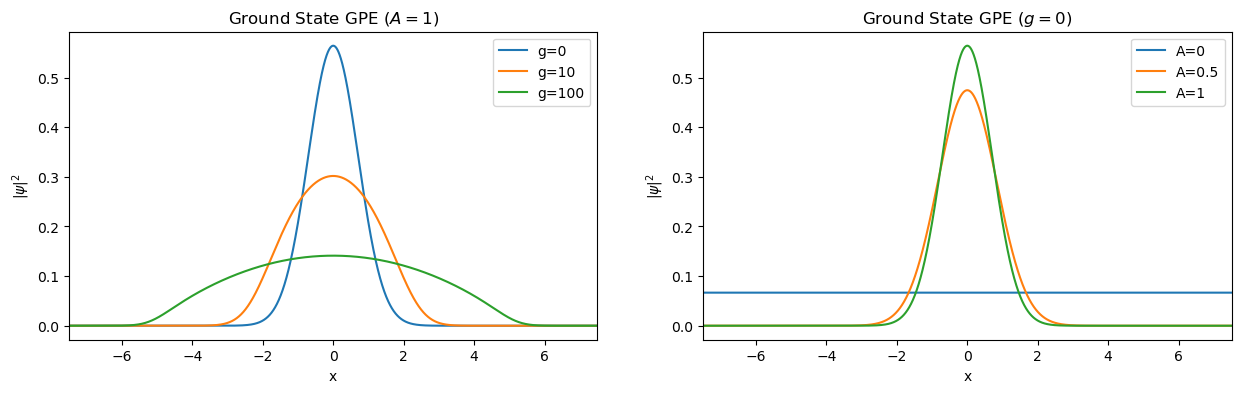

In [151]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4))

ax1.plot(x, np.abs(psi_g0)**2,label = "g=0")
ax1.plot(x, np.abs(psi_g10)**2 ,label = "g=10")
ax1.plot(x, np.abs(psi_g100)**2 ,label = "g=100")

ax1.set_xlim(-7.5,7.5)
ax1.legend()

ax2.plot(x, np.abs(psi_A0)**2,label = "A=0")
ax2.plot(x, np.abs(psi_A05)**2 ,label = "A=0.5")
ax2.plot(x, np.abs(psi_A1)**2 ,label = "A=1")

ax2.set_xlim(-7.5,7.5)
ax2.legend()

ax1.set_title("Ground State GPE " r"$(A=1)$")
ax2.set_title("Ground State GPE " r"$(g=0)$")

ax1.set(ylabel=r'$|\psi|^2$', xlabel=r'x')
ax2.set(ylabel=r'$|\psi|^2$', xlabel=r'x')

plt.savefig('DensityDist.png', dpi=500, bbox_inches='tight') 
plt.show

In [159]:
k = np.fft.fftshift(wavenumbers) # reorder k: negative -> positive (used to plot) 
def momentumDist (psi, x):
    dk = 2 * np.pi / (len(x) * dx) # spacing in k

    phi = dx / np.sqrt(2.0 * np.pi) *np.fft.fftshift(np.fft.fft(np.fft.ifftshift(psi)))
    
    #phi = np.fft.fftshift(fft(np.abs(psi)**2)*dk)/ np.sqrt(2*np.pi)  # momentum-space wavefunction
    return phi     

In [160]:
phi_g0 =  momentumDist(psi_g0, k) 
phi_g10 = momentumDist(psi_g10, k) 
phi_g100 =momentumDist(psi_g100, k) 

phi_A0 =  momentumDist(psi_A0, k) 
phi_A05 = momentumDist(psi_A05, k) 
phi_A1 =  momentumDist(psi_A1, k) 

<function matplotlib.pyplot.show(close=None, block=None)>

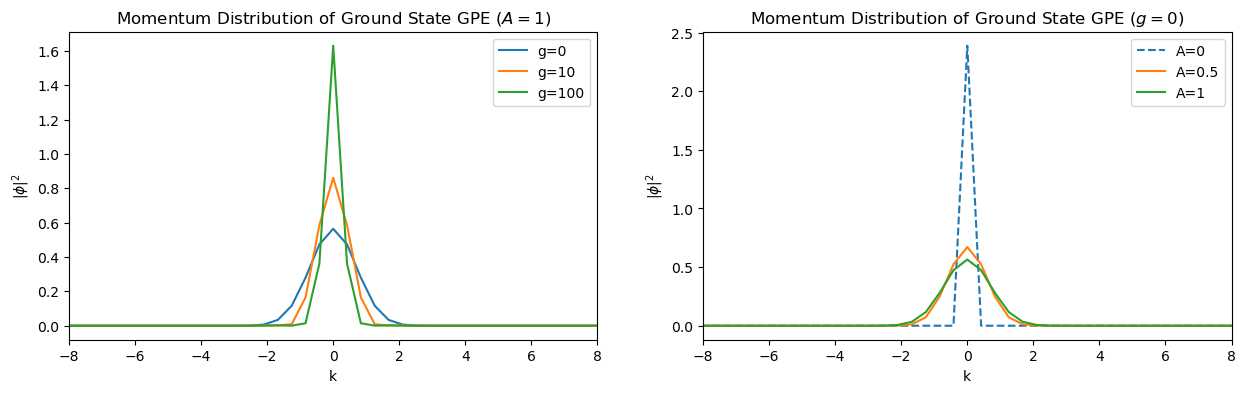

In [161]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4))

ax1.plot(k, np.abs(phi_g0)**2,label = "g=0")
ax1.plot(k, np.abs(phi_g10)**2 ,label = "g=10")
ax1.plot(k, np.abs(phi_g100)**2 ,label = "g=100")

ax1.set_xlim(-8,8)
ax1.legend()

ax2.plot(k, np.abs(phi_A0)**2, '--', label = "A=0")
ax2.plot(k, np.abs(phi_A05)**2 ,label = "A=0.5")
ax2.plot(k, np.abs(phi_A1)**2 ,label = "A=1")

ax2.set_xlim(-8,8)
ax2.legend()

ax1.set_title("Momentum Distribution of Ground State GPE " r"$(A=1)$")
ax2.set_title("Momentum Distribution of Ground State GPE " r"$(g=0)$")

ax1.set(ylabel=r'$|\phi|^2$', xlabel=r'k')
ax2.set(ylabel=r'$|\phi|^2$', xlabel=r'k')

plt.savefig('MomentumDist.png', dpi=500, bbox_inches='tight') 
plt.show

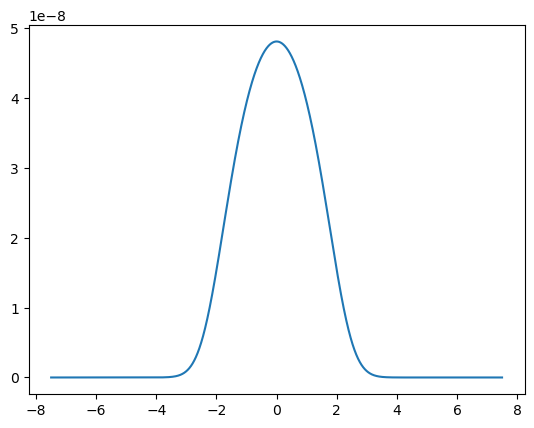

In [210]:
k = np.fft.fftshift(wavenumbers)                          # k axis, increasing
dk = 2*np.pi / (len(x) * dx)                       # spacing in k

phi = np.fft.fftshift(fft(psi)) * dx / np.sqrt(2*np.pi)   # momentum-space wavefunction

dk = 2 * np.pi / (len(x) * dx)
psi = ifft(phi)

plt.plot(x, np.abs(psi)**2) 


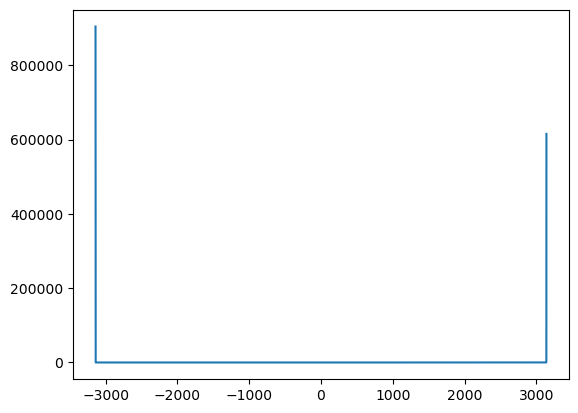

In [205]:
plt.plot(k, np.abs(phi)**2*dk / np.sqrt(2.0 * np.pi))
#plt.xlim(-8, 8)

#plt.ylim(0, 0.000008)


## With DDI 

Effective Interaction Term : $$\Phi(x)=\textcolor{blue}{iFFT}\{U(k)\textcolor{blue}{FFT}\{|\psi|^2\}\}$$
an aproximate result for $U(k)$ : $$U(k)= \cancel{\frac{g_{s}}{2\pi l^{2}}}+\frac{g_{dd}}{2\pi l^{2}} \frac{[3(Q^{2}e^{ Q^{2} }\,\text{Ei}(-Q^{2})+1]}{1+\eta}-1$$
where
- $Q = \frac{1}{\sqrt{2}}k \eta^{1/4}l$ 
- Ei : exponential integral : $Ei(-Q^{2})= -\int^{\infty}_{-\infty}\frac{e^{ -(-Q^{2}) }}{Q^{2}}d(Q^{2})$
    - can also be written in terms of the incomplete Gamma Function $\Gamma$ using $Ei(-x)=-\Gamma(0,x)$ 
    - Limiting behaviours $$\begin{align}U(k)\cases{\frac{g_{dd}}{2\pi l^{2}} \frac{2-\eta}{1+\eta}, \quad k \to{0} \\ - \frac{g_{dd}}{2\pi l^{2}}, \qquad k \to \infty}\end{align}$$


#### To find U(k)

(-11.5, 11.5)

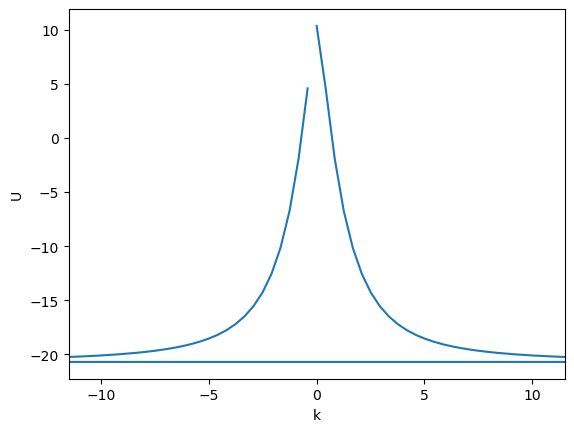

In [250]:
U = np.zeros(len(wavenumbers)) 

l = 1 
eta = 1
g_dd = 130
Q = (1/np.sqrt(2))*wavenumbers*eta**(1/4)*l
Qsq = Q**2
Ei = expi(-Q**2)
term = np.zeros(len(wavenumbers))
U = np.zeros(len(Qsq)) 

for i in range(len(wavenumbers)) :
    if Qsq[i] == 0: 
        U[i] = (g_dd/(2*np.pi*l**2))*((2-eta)/(1+eta))
        
    elif (Qsq[i]>0) & (Qsq[i]<=500) : 
        U[i] = (g_dd/(2*np.pi*l**2))*(3*(Qsq[i]*np.exp(Qsq[i])*Ei[i]+1)/(1+eta)-1)

    elif Qsq[i] >500 : 
        U[i] = - g_dd/(2*np.pi*l**2)
    
        

#print(U)

plt.plot(wavenumbers,U)
plt.xlabel('k')

plt.ylabel ('U')
plt.xlim(-11.5,11.5)

In [260]:
dx = 0.001; #space steps 
x = np.arange(-7.5, 7.5, dx) # space array

dt = 1e-3 #time step
no_tsteps = int(100/dt) 

A=1 # Harmonic trap strength
g=1 # interaction strength

psi = np.zeros(len(x), dtype=complex)

gamma = (1+1j) # imaginary time (if gamma = 0 -> real time ) 
c0 = dt / (1j - gamma) # -dt 

wavenumbers = 2*np.pi*fftfreq(len(x), d=dx) # wavenumbers 'grid'

V = 0.5*A*x**2 # trapping potential 
kinetic_array = np.exp(c0 * 0.5 * wavenumbers**2) #kinetic

def normalize(psi) : 
    return psi/np.sqrt(np.sum(np.abs(psi) ** 2) * dx)

def DDI(psi, U) : 
    Phi = ifft(U*fft(np.abs(psi)**2))
    return Phi

def kinetic(psi) : 
    psi = ifft(fft(psi)*kinetic_array) # kinetic evolution (USing FFT) 
    return psi

def local(psi) :
    psi_density = np.abs(psi)**2
    Phi = DDI(psi, U) 
    psi *= np.exp(c0*(V+g*psi_density+Phi)) # Trapping Potential + Interaction
    return psi 

def evolution(psi): 
    psi = kinetic(psi)
    psi = local(psi)

    psi = normalize(psi)
    return psi

def energy(psi):
    dpsi = (np.roll(psi, -1) - np.roll(psi, 1)) / (2 *dx) #centered finite difference
    #dpsi = ifft(1j * wavenumbers * fft(psi))
    E_kinetic = 0.5 * np.sum(np.abs(dpsi)**2) * dx
    E_potential = np.sum(V * np.abs(psi)**2) * dx
    E_interaction = 0.5 * g * np.sum(np.abs(psi)**4) * dx
    return E_kinetic, E_potential , E_interaction

psi=(np.exp(-0.5 * x**2) / np.pi**0.25).astype(complex) #initial state (From Gaussian Shape)
psi = normalize(psi)

# energy convergence 
E_prev = sum(energy(psi))
print(f"Initial Energy E_0 = {E_prev:.10f}")

for i in range(no_tsteps): 
    psi = evolution(psi)
    E_kinetic, E_potential , E_interaction = energy(psi)
    E_curr = E_kinetic+ E_potential + E_interaction

    E_diff = abs(E_curr - E_prev) 

    if i % 1000 == 0 or E_diff < 1e-13 : 
        print(f"step {i} = {E_curr:.13f}") 
        print(f"Potential Energy : {E_potential:.13f} | Kinetic Energy : {E_kinetic:.13f} | Interaction : {E_interaction:.13f}\n")

    if E_diff < 1e-13 : 
        print(f"\nConvergence achieved at step {i}!")
        print(f"Ground State Energy E_g  = {E_curr:.13f}")
        
        break

    E_prev = E_curr
        

Initial Energy E_0 = 0.6994710152
step 0 = 0.6998726952455
Potential Energy : 0.2492756336201 | Kinetic Energy : 0.2507292290480 | Interaction : 0.1998678325774

step 1000 = 15.2601132108354
Potential Energy : 0.0050674265515 | Kinetic Energy : 13.7418360382036 | Interaction : 1.5132097460802

step 1160 = 15.2601132113514
Potential Energy : 0.0050674265512 | Kinetic Energy : 13.7418360386927 | Interaction : 1.5132097461074


Convergence achieved at step 1160!
Ground State Energy E_g  = 15.2601132113514


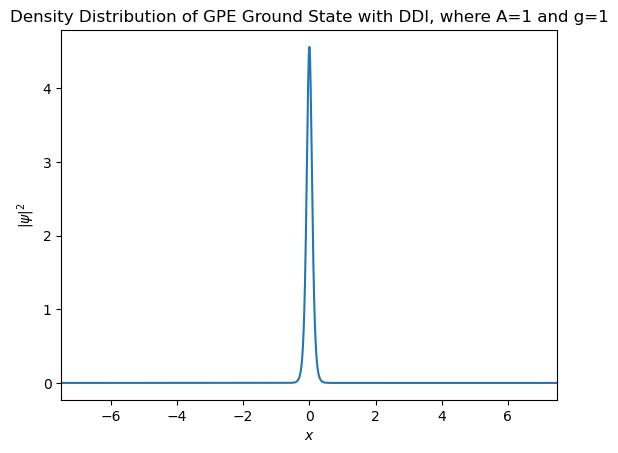

In [261]:
plt.plot(x, np.abs(psi)**2) 
plt.xlim(-7.5, 7.5)
plt.ylabel (r'$|\psi|^2$')
plt.xlabel (r'$x$')
#plt.ylim (0, 0.6) 
plt.title(f"Density Distribution of GPE Ground State with DDI, where A={A} and g={g}")

plt.savefig('DensityDistwDDI_A1_g1.png', dpi=500, bbox_inches='tight') 
plt.show()

In [211]:
def groundstateGPE_wDDI (A, g, g_dd, qU) : 
    dx = 0.001; #space steps 
    x = np.arange(-7.5, 7.5, dx) # space array
    
    dt = 1e-3 #time step
    no_tsteps = int(100/dt) 
    
    psi = np.zeros(len(x), dtype=complex)
    
    gamma = (1+1j) # imaginary time (if gamma = 0 -> real time ) 
    c0 = dt / (1j - gamma) # -dt 
    
    wavenumbers = 2*np.pi*fftfreq(len(x), d=dx) # wavenumbers 'grid'
    
    V = 0.5*A*x**2 # trapping potential 
    kinetic = np.exp(c0 * 0.5 * wavenumbers**2) #kinetic
    
    def normalize(psi) : 
        return psi/np.sqrt(np.sum(np.abs(psi) ** 2) * dx)

            
    def evolution(psi): 
        psi_density = np.abs(psi)**2
        psi = ifft(fft(psi)*kinetic) # kinetic evolution (USing FFT)
        Phi, U = DDI(psi, wavenumbers) 
        psi *= np.exp(c0*(V+g*psi_density+Phi)) # Trapping Potential + Interaction
    
        psi = normalize(psi)
        return psi
    
    def energy(psi):
        dpsi = (np.roll(psi, -1) - np.roll(psi, 1)) / (2 *dx) # spectral derivative
        #dpsi = ifft(1j * wavenumbers * fft(psi))
        E_kinetic = 0.5 * np.sum(np.abs(dpsi)**2) * dx
        E_potential = np.sum(V * np.abs(psi)**2) * dx
        E_interaction = 0.5 * g * np.sum(np.abs(psi)**4) * dx
        return E_kinetic, E_potential , E_interaction
    
    psi=(np.exp(-0.5 * x**2) / np.pi**0.25).astype(complex) #initial state (From Gaussian Shape)
    psi = normalize(psi)
    
    # energy convergence 
    E_prev = sum(energy(psi) )
    #print(f"Initial Energy E_0 = {E_prev:.10f}")
    
    
    for i in range(no_tsteps): 
        psi = evolution(psi)
        E_kinetic, E_potential , E_interaction = energy(psi)
        E_curr = E_kinetic+ E_potential + E_interaction
    
        E_diff = abs(E_curr - E_prev) 
    
       # if i % 1000 == 0 or E_diff < 1e-13 : 
           # print(f"step {i} = {E_curr:.13f}") 
           # print(f"Potential Energy : {E_potential:.13f}, Kinetic Energy : {E_kinetic:.13f}, Interaction : {E_interaction:.13f}\n")
    
        if E_diff < 1e-13 : 
            print(f"Done, For g = {g}, A = {A} \nConvergence achieved at step {i}!, Ground State Energy E_g  = {E_curr:.13f}") 
            break
            #print(f"\nConvergence achieved at step {i}!")
            #print(f"Ground State Energy E_g  = {E_curr:.13f}")
            
    
        E_prev = E_curr

    return psi, U

C:\Users\Aisya Jasmin\AppData\Local\Temp\ipykernel_16360\1968318395.py:43: RuntimeWarning: overflow encountered in exp
  U[i] = (g_dd/(2*np.pi*l**2))*(3*(Qsq*(np.exp(Qsq)*Ei+1)/(1+eta)-1))
C:\Users\Aisya Jasmin\AppData\Local\Temp\ipykernel_16360\1968318395.py:43: RuntimeWarning: invalid value encountered in multiply
  U[i] = (g_dd/(2*np.pi*l**2))*(3*(Qsq*(np.exp(Qsq)*Ei+1)/(1+eta)-1))


ValueError: setting an array element with a sequence.